# 5주차 · 금융 데이터의 가공 및 분석 — 완성본

**인공지능과 데이터 활용** · 국내 주요 종목(삼성전자·SK하이닉스·현대차)의 **실제 KRX 일별 시세**로
전통적 기술적 분석을 직접 계산하고, 같은 표로 만든 **AI 보조 요약**의 정확성을 검증합니다.

| 워크북 | 내용 | 산출물 |
|---|---|---|
| 1. 시세 수집과 전처리 | KRX 다운로드 형식 원본 → 분석용 데이터 | `week05_clean_3stocks.csv` |
| 2. 기술적 분석 | 수익률·SMA·RSI·볼린저밴드·변동성·MDD, 차트 | `week05_indicators_latest.csv`, 그림 |
| 3. AI 보조 요약 검증 | 근거 표 → AI 프롬프트 → 숫자·표현 검증 | `week05_ai_verification.csv` |

**실행 방법:** Colab 메뉴 `런타임 → 모두 실행`. 데이터는 GitHub에서 읽고, 접속이 안 되면 **Google Drive에 미리 저장해 둔 같은 데이터**를 자동으로 사용합니다(아래 0장 `DATA_SOURCE`). API 키는 필요 없습니다.


> 데이터 출처: 한국거래소(KRX) 일별 시세(2025-01-02 ~ 2026-10-13, 431거래일). 이 노트북은 교육용 분석이며 매매 추천이 아닙니다.

## 0. 실행 환경 준비

In [1]:
# 그래프 한글 표시용 패키지 (Colab에서 처음 한 번 설치, 약 10초)
!pip -q install koreanize-matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib            # import만 하면 그래프에서 한글이 깨지지 않음

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

STOCKS = {"005930": "삼성전자", "000660": "SK하이닉스", "005380": "현대차"}
print("pandas", pd.__version__)

pandas 3.0.5


### 데이터 위치 선택
- 기본값 `"auto"`: GitHub에서 읽고, 안 되면 **내 Google Drive에 미리 저장된 데이터**를 자동으로 찾습니다.
- 수업 중 GitHub 대신 Drive 데이터를 쓰려면 `DATA_SOURCE = "drive"` 로 바꿉니다. (처음 한 번 Drive 접근 허용 창이 뜹니다)
- Drive 연결도 어렵다면 `"upload"`: 미리 내려받은 CSV를 직접 업로드합니다.
- 어느 경로든 **같은 파일(MD5 확인)** 이므로 기대값이 똑같이 나옵니다.

In [3]:
# ── 데이터 위치 선택 ────────────────────────────────────────────────
# "auto"   : GitHub에서 읽고, 접속이 안 되면 내 Google Drive에서 자동으로 찾음 (기본)
# "drive"  : 내 Google Drive에 미리 저장해 둔 데이터 사용 (수업 중 권장 대안)
# "upload" : Drive에서 내려받아 둔 CSV 파일을 지금 직접 업로드
# "github" : GitHub에서만 읽음
DATA_SOURCE = "auto"

import os, glob, hashlib, io, urllib.request

GITHUB_BASE = "https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week05/data/"
MANIFEST = "week05_MANIFEST.csv"

def _find_in_drive():
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    for depth in range(0, 7):                       # 내 드라이브 아래 6단계까지 탐색
        pattern = "/content/drive/MyDrive/" + "*/" * depth + MANIFEST
        hits = sorted(glob.glob(pattern))
        if hits:
            return os.path.dirname(hits[0]) + "/"
    raise FileNotFoundError(
        "내 Drive에서 " + MANIFEST + " 를 찾지 못했습니다.\n"
        "· 강의자: '강의5주/02_데이터' 폴더에 Week05_00_데이터준비 노트북을 먼저 실행하세요.\n"
        "· 학생: 공유받은 '02_데이터' 폴더를 오른쪽 클릭 → '바로가기 추가' → '내 드라이브'에 추가한 뒤 다시 실행하세요.")

def _upload():
    from google.colab import files
    os.makedirs("week05_data", exist_ok=True)
    print("02_데이터 폴더에서 내려받은 CSV(+ week05_MANIFEST.csv)를 모두 선택하세요.")
    for name, data in files.upload().items():
        open(os.path.join("week05_data", name), "wb").write(data)
    return "week05_data/"

def resolve_base(source=DATA_SOURCE):
    if source in ("auto", "github"):
        try:
            urllib.request.urlopen(GITHUB_BASE + MANIFEST, timeout=10).read()
            return GITHUB_BASE
        except Exception as e:
            if source == "github":
                raise
            print("GitHub 접속 실패 → Google Drive에서 찾습니다:", type(e).__name__)
            source = "drive"
    if source == "drive":
        return _find_in_drive()
    if source == "upload":
        return _upload()
    if os.path.isdir(source):                       # 로컬 폴더 경로를 직접 지정한 경우
        return source.rstrip("/") + "/"
    raise ValueError("DATA_SOURCE 값을 확인하세요: " + str(source))

def _read_bytes(base, name):
    if base.startswith("http"):
        return urllib.request.urlopen(base + name, timeout=30).read()
    return open(base + name, "rb").read()

BASE = resolve_base()
man = pd.read_csv(io.BytesIO(_read_bytes(BASE, MANIFEST)))
def _status(f, md5):
    if BASE.startswith("http"):
        return "GitHub 원본"
    if not os.path.exists(BASE + f):
        return "⚠ 파일 없음"
    return "정상(MD5 일치)" if hashlib.md5(_read_bytes(BASE, f)).hexdigest() == md5 else "⚠ 내용이 수업 원본과 다름"
man["상태"] = [_status(f, m) for f, m in zip(man["file"], man["md5"])]
print("데이터 위치:", BASE)
man[["file", "rows", "상태"]]

데이터 위치: https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week05/data/


,file,rows,상태
0,kosdaq_daily.csv,431,GitHub 원본
1,kospi_daily.csv,431,GitHub 원본
2,krx_daily_000660.csv,431,GitHub 원본
3,krx_daily_005380.csv,431,GitHub 원본
4,krx_daily_005930.csv,431,GitHub 원본
5,krx_daily_3stocks_raw_ko.csv,1293,GitHub 원본


---
# 워크북 1 · 국내 주식 시세 수집과 전처리

### 데이터를 어디서 구하나? (확보 경로 5가지)
| 방법 | API 키 | 이번 실습 | 비고 |
|---|---|---|---|
| **A. 수업 저장소 CSV (KRX 실제 시세)** | 없음 | ✅ 기본 | 모두 같은 값 → 결과 대조 가능 |
| B. FinanceDataReader `fdr.DataReader('005930')` | 없음 | 선택 | 네이버 차트 서버 경유, 접속 제한 시 실패 |
| C. 공공데이터포털 금융위원회_주식시세정보 | 서비스키 | 심화 | 공식 공공데이터, 전 영업일까지 제공 |
| D. KRX Open API | AUTH_KEY | 심화 | 1회 호출 = 하루치 전종목 |
| E. 네이버 금융 화면 | 없음 | 교차검증 | 몇 개 값을 눈으로 대조. 자동 수집(스크래핑) 금지 |

B~D는 `Week05_데이터수집_API가이드.ipynb`에서 따라 할 수 있습니다.

원본 파일 `krx_daily_3stocks_raw_ko.csv`는 KRX 정보데이터시스템 **전종목 시세** 다운로드와 같은 모양입니다
(한글 열 이름, 최신일이 맨 위, 날짜가 `2026/10/13` 같은 문자열).

### 1-1. 원본 불러오기

In [4]:
raw = pd.read_csv(BASE + "krx_daily_3stocks_raw_ko.csv", dtype={"종목코드": str})
print("원본 크기(행, 열):", raw.shape)
raw.head()

원본 크기(행, 열): (1293, 14)


,일자,종목코드,종목명,시장구분,종가,대비,등락률,시가,고가,저가,거래량,거래대금,시가총액,상장주식수
0,2026/10/13,000660,SK하이닉스,KOSPI,1443000,-162000,-10.09,1538000,1554000,1425000,5455791,8018763093463,1054100482695000,730492365
1,2026/10/13,005380,현대차,KOSPI,315000,-5000,-1.56,307500,315500,299000,889861,272121103866,64091944980000,203466492
2,2026/10/13,005930,삼성전자,KOSPI,232000,-18500,-7.39,241500,244000,228000,26790913,6242963049500,1356336637056000,5846278608
3,2026/10/12,000660,SK하이닉스,KOSPI,1605000,-76000,-4.52,1640000,1653000,1605000,3113644,5055895886104,1172440245825000,730492365
4,2026/10/12,005380,현대차,KOSPI,320000,-4500,-1.39,320000,334000,318500,676183,218597668250,65109277440000,203466492


**관찰 질문**  ① 날짜는 오름차순인가 내림차순인가?  ② `일자` 열의 자료형은?  ③ `dtype={"종목코드": str}`를 빼면 어떻게 될까? (아래 셀)

In [5]:
raw.info()

# dtype을 지정하지 않으면 종목코드 앞자리 0이 사라진다 → 005930이 5930이 됨
bad = pd.read_csv(BASE + "krx_daily_3stocks_raw_ko.csv")
print("\n자료형 지정 없이 읽은 종목코드:", sorted(bad["종목코드"].unique()))

<class 'pandas.DataFrame'>
RangeIndex: 1293 entries, 0 to 1292
Data columns (total 14 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   일자      1293 non-null   str    
 1   종목코드    1293 non-null   str    
 2   종목명     1293 non-null   str    
 3   시장구분    1293 non-null   str    
 4   종가      1293 non-null   int64  
 5   대비      1293 non-null   int64  
 6   등락률     1293 non-null   float64
 7   시가      1293 non-null   int64  
 8   고가      1293 non-null   int64  
 9   저가      1293 non-null   int64  
 10  거래량     1293 non-null   int64  
 11  거래대금    1293 non-null   int64  
 12  시가총액    1293 non-null   int64  
 13  상장주식수   1293 non-null   int64  
dtypes: float64(1), int64(9), str(4)
memory usage: 182.8 KB

자료형 지정 없이 읽은 종목코드: [np.int64(660), np.int64(5380), np.int64(5930)]


### 1-2. 열 이름 영문화 · 자료형 변환

In [6]:
KO2EN = {"일자": "Date", "종목코드": "Code", "종목명": "Name", "시장구분": "Market",
         "종가": "Close", "대비": "Changes", "등락률": "ChangesRatio", "시가": "Open",
         "고가": "High", "저가": "Low", "거래량": "Volume", "거래대금": "Amount",
         "시가총액": "Marcap", "상장주식수": "Stocks"}
PRICE_COLS = ["Open", "High", "Low", "Close", "Volume"]

df = raw.rename(columns=KO2EN).copy()
df["Code"] = df["Code"].str.zfill(6)                                      # 6자리 보장
df["Date"] = pd.to_datetime(df["Date"], format="%Y/%m/%d", errors="coerce")  # 문자열 → 날짜
for c in PRICE_COLS + ["Amount", "Changes", "ChangesRatio", "Marcap", "Stocks"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")                         # 숫자가 아니면 NaN
df.dtypes

Date            datetime64[us]
Code                       str
Name                       str
Market                     str
Close                    int64
Changes                  int64
ChangesRatio           float64
Open                     int64
High                     int64
Low                      int64
Volume                   int64
Amount                   int64
Marcap                   int64
Stocks                   int64
dtype: object

### 1-3. 품질 점검 — 결측·중복·논리 오류

In [7]:
check = {
    "날짜 변환 실패": int(df["Date"].isna().sum()),
    "가격·거래량 결측 행": int(df[PRICE_COLS].isna().any(axis=1).sum()),
    "중복(종목+일자)": int(df.duplicated(["Code", "Date"]).sum()),
    # 고가는 시가·종가·저가보다 작을 수 없고, 저가는 시가·종가보다 클 수 없다
    "OHLC 논리 오류": int(((df["High"] < df[["Open", "Close", "Low"]].max(axis=1)) |
                         (df["Low"] > df[["Open", "Close"]].min(axis=1))).sum()),
    "거래량 0 (거래정지 의심)": int((df["Volume"] == 0).sum()),
    "날짜 오름차순 여부": bool(df.groupby("Code")["Date"].apply(lambda s: s.is_monotonic_increasing).all()),
}
pd.Series(check, name="점검 결과").to_frame()

,점검 결과
날짜 변환 실패,0
가격·거래량 결측 행,0
중복(종목+일자),0
OHLC 논리 오류,0
거래량 0 (거래정지 의심),0
날짜 오름차순 여부,False


✔ **기대값:** 날짜 변환 실패 0 · 결측 0 · 중복 0 · OHLC 논리 오류 0 · 거래량 0인 날 0 · **날짜 오름차순 False** (원본이 내림차순이므로)

이동평균·수익률은 "어제 → 오늘" 순서로 계산하므로 **반드시 오름차순으로 정렬**해야 합니다.

### 1-4. 정렬 · 저장

In [8]:
clean = (df.dropna(subset=["Date", "Close"])
           .drop_duplicates(["Code", "Date"])
           .sort_values(["Code", "Date"])
           .reset_index(drop=True))
clean.to_csv("week05_clean_3stocks.csv", index=False, encoding="utf-8-sig")

summary = clean.groupby("Name").agg(시작일=("Date", "min"), 종료일=("Date", "max"), 거래일수=("Date", "count"),
                                    첫종가=("Close", "first"), 마지막종가=("Close", "last"))
print("원본", len(raw), "행 → 정제", len(clean), "행")
summary

원본 1293 행 → 정제 1293 행


,시작일,종료일,거래일수,첫종가,마지막종가
Name,,,,,
SK하이닉스,2025-01-02,2026-10-13,431,171200,1443000
삼성전자,2025-01-02,2026-10-13,431,53400,232000
현대차,2025-01-02,2026-10-13,431,211500,315000


### 1-5. 교차검증 ① — 제공된 정제본과 같은가?

In [9]:
def load_stock(code):
    d = pd.read_csv(BASE + f"krx_daily_{code}.csv", dtype={"Code": str}, parse_dates=["Date"])
    return d.sort_values("Date").reset_index(drop=True)

for code, name in STOCKS.items():
    mine = clean[clean["Code"] == code].reset_index(drop=True)
    ref = load_stock(code)
    same = len(mine) == len(ref) and (mine[PRICE_COLS].values == ref[PRICE_COLS].values).all()
    print(f"{name}({code}) {len(mine)}행 · 제공본과 OHLCV 일치: {same}")

삼성전자(005930) 431행 · 제공본과 OHLCV 일치: True


SK하이닉스(000660) 431행 · 제공본과 OHLCV 일치: True


현대차(005380) 431행 · 제공본과 OHLCV 일치: True


### 1-6. 교차검증 ② — 네이버 금융 화면과 대조 (직접 확인)
아래 링크를 열어 **2026.10.13 종가**가 표의 값과 같은지 확인하고 체크리스트에 기록합니다. (화면을 보는 것만 하고 자동 수집은 하지 않습니다.)

| 종목 | 네이버 금융 일별 시세 | 이 데이터의 2026-10-13 종가 |
|---|---|---|
| 삼성전자 | https://finance.naver.com/item/sise_day.naver?code=005930 | 아래 셀 출력 |
| SK하이닉스 | https://finance.naver.com/item/sise_day.naver?code=000660 | 〃 |
| 현대차 | https://finance.naver.com/item/sise_day.naver?code=005380 | 〃 |

> 수업일 기준으로 몇 주가 지났다면 페이지 하단의 페이지 번호를 넘겨 해당 날짜를 찾습니다. 일별 시세 화면의 종가는 수정주가가 아니라 당일 실제 종가입니다.

In [10]:
clean[clean["Date"] == "2026-10-13"][["Name", "Date", "Open", "High", "Low", "Close", "Volume"]]

,Name,Date,Open,High,Low,Close,Volume
430,SK하이닉스,2026-10-13,1538000,1554000,1425000,1443000,5455791
861,현대차,2026-10-13,307500,315500,299000,315000,889861
1292,삼성전자,2026-10-13,241500,244000,228000,232000,26790913


In [11]:
# 수집 기록(provenance) — 보고서 첫 줄에 그대로 붙여 넣는다
record = {"출처": "한국거래소(KRX) 일별 시세 (수업 저장소 Week05/data, 원천: FinanceData/marcap)",
          "종목": ", ".join(f"{n}({c})" for c, n in STOCKS.items()),
          "기간": f"{clean['Date'].min().date()} ~ {clean['Date'].max().date()}",
          "가격 유형": "수정주가 아님(당일 실제 체결가)", "원본 행수": len(raw), "정제 행수": len(clean),
          "분석 실행 시각": pd.Timestamp.now(tz="Asia/Seoul").strftime("%Y-%m-%d %H:%M")}
pd.Series(record).to_frame("수집 기록")

,수집 기록
출처,"한국거래소(KRX) 일별 시세 (수업 저장소 Week05/data, 원천: Fina..."
종목,"삼성전자(005930), SK하이닉스(000660), 현대차(005380)"
기간,2025-01-02 ~ 2026-10-13
가격 유형,수정주가 아님(당일 실제 체결가)
원본 행수,1293
정제 행수,1293
분석 실행 시각,2026-10-15 06:55


---
# 워크북 2 · 주요 종목 기술적 분석

| 지표 | 계산식 | 해석할 때 |
|---|---|---|
| 일간 수익률(%) | (오늘 종가 ÷ 어제 종가 − 1) × 100 | 첫날은 NaN |
| 누적 수익률(%) | (오늘 종가 ÷ 첫날 종가 − 1) × 100 | 종목 간 크기 비교 가능 |
| SMA5·20·60 | 최근 5·20·60거래일 종가 평균 | 처음 n−1일은 NaN |
| 골든/데드 크로스 | SMA5가 SMA20을 위로/아래로 뚫은 날 | 사후 관찰일 뿐, 신호 아님 |
| RSI14 | 100 − 100/(1+RS), RS = 14일 평균 상승폭 ÷ 평균 하락폭 | 단순평균(수업) vs Wilder(HTS 다수) |
| 볼린저밴드 | SMA20 ± 2 × 20일 종가 표준편차 | 밴드 밖 = 최근 20일 대비 이례적 |
| 20일 변동성(%p) | 최근 20개 일간 수익률의 표준편차 | ×√252 하면 연율화 |
| 최대낙폭(MDD) | 고점 대비 가장 크게 떨어진 비율 | 위험의 크기 |

### 2-1. 지표 계산 함수

In [12]:
def rsi(close, n=14, method="sma"):
    delta = close.diff()
    gain, loss = delta.clip(lower=0), -delta.clip(upper=0)
    if method == "wilder":                                   # 지수평활(1/n)
        avg_g = gain.ewm(alpha=1/n, adjust=False, min_periods=n).mean()
        avg_l = loss.ewm(alpha=1/n, adjust=False, min_periods=n).mean()
    else:                                                    # 단순 이동평균
        avg_g = gain.rolling(n, min_periods=n).mean()
        avg_l = loss.rolling(n, min_periods=n).mean()
    out = 100 - 100 / (1 + avg_g / avg_l.replace(0, np.nan))
    out[(avg_l == 0) & (avg_g > 0)] = 100.0                  # 14일 내내 상승
    out[(avg_l == 0) & (avg_g == 0)] = 50.0                  # 14일 내내 보합
    return out

def add_indicators(df):
    d = df.sort_values("Date").copy()
    c = d["Close"]
    d["ReturnPct"] = c.pct_change() * 100
    d["CumReturnPct"] = (c / c.iloc[0] - 1) * 100
    for n in (5, 20, 60):
        d[f"SMA{n}"] = c.rolling(n, min_periods=n).mean()
    above = (d["SMA5"] > d["SMA20"]).astype(float).where(d["SMA20"].notna())
    d["Cross"] = np.select([(above == 1) & (above.shift() == 0), (above == 0) & (above.shift() == 1)],
                           ["golden", "dead"], default="")
    d["RSI14"] = rsi(c, 14, "sma")
    d["RSI14_Wilder"] = rsi(c, 14, "wilder")
    mid, sd = c.rolling(20, min_periods=20).mean(), c.rolling(20, min_periods=20).std()
    d["BB_Upper"], d["BB_Lower"] = mid + 2 * sd, mid - 2 * sd
    d["Vol20Pct"] = d["ReturnPct"].rolling(20, min_periods=20).std()
    d["DrawdownPct"] = (c / c.cummax() - 1) * 100
    return d

### 2-2. 세 종목에 적용

In [13]:
frames = {name: add_indicators(clean[clean["Code"] == code]) for code, name in STOCKS.items()}
show = ["Date", "Close", "ReturnPct", "SMA5", "SMA20", "RSI14", "BB_Upper", "BB_Lower", "Vol20Pct", "Cross"]
frames["삼성전자"][show].set_index("Date").tail(8).round(2)

,Close,ReturnPct,SMA5,SMA20,RSI14,BB_Upper,BB_Lower,Vol20Pct,Cross
Date,,,,,,,,,
2026-09-30,268500,-1.47,274600.0,263300.0,49.39,284600.85,241999.15,2.95,
2026-10-01,276000,2.79,274500.0,264050.0,53.63,286054.54,242045.46,3.01,
2026-10-02,276000,0.00,272600.0,265325.0,53.93,286976.00,243674.00,2.83,
2026-10-06,272000,-1.45,273000.0,266425.0,57.49,287006.74,245843.26,2.86,
2026-10-07,268500,-1.29,272200.0,267075.0,62.75,287015.11,247134.89,2.86,
2026-10-08,262000,-2.42,270900.0,266675.0,58.18,286688.88,246661.12,2.62,
2026-10-12,250500,-4.39,265800.0,265725.0,48.31,286941.86,244508.14,2.79,
2026-10-13,232000,-7.39,257000.0,263850.0,40.38,289769.10,237930.90,3.20,dead


### 2-3. 자가 점검 — 내 계산이 맞는가?

In [14]:
d = frames["삼성전자"]
manual_sma5 = d["Close"].tail(5).mean()                       # 손으로 계산한 마지막 날 SMA5
print("마지막 날 SMA5  함수:", round(d["SMA5"].iloc[-1], 1), "| 직접:", round(manual_sma5, 1))
print("SMA20 NaN 개수(19여야 정상):", int(d["SMA20"].isna().sum()))
print("RSI14 NaN 개수(14여야 정상):", int(d["RSI14"].isna().sum()))
assert abs(d["SMA5"].iloc[-1] - manual_sma5) < 1e-6
assert d["SMA20"].isna().sum() == 19 and d["RSI14"].isna().sum() == 14
print("✔ 자가 점검 통과")

마지막 날 SMA5  함수: 257000.0 | 직접: 257000.0
SMA20 NaN 개수(19여야 정상): 19
RSI14 NaN 개수(14여야 정상): 14
✔ 자가 점검 통과


### 2-4. 기준일 지표표 (워크북 2 결과표 = 워크북 3의 AI 입력)

In [15]:
def latest_table(frames, date=None):
    rows = []
    for name, d in frames.items():
        x = d[d["Date"] <= pd.Timestamp(date)] if date else d
        last = x.iloc[-1]
        rows.append({"종목": name, "기준일": last["Date"].strftime("%Y-%m-%d"), "종가": int(last["Close"]),
                     "일간수익률%": round(float(last["ReturnPct"]), 2),
                     "SMA5": int(round(last["SMA5"])), "SMA20": int(round(last["SMA20"])),
                     "RSI14": round(float(last["RSI14"]), 1), "Vol20Pct": round(float(last["Vol20Pct"]), 2),
                     "BB_Upper": int(round(last["BB_Upper"])), "BB_Lower": int(round(last["BB_Lower"]))})
    t = pd.DataFrame(rows)
    t["변동성순위"] = t["Vol20Pct"].rank(ascending=False).astype(int)
    return t

table = latest_table(frames)
table.to_csv("week05_indicators_latest.csv", index=False, encoding="utf-8-sig")
table

,종목,기준일,종가,일간수익률%,SMA5,SMA20,RSI14,Vol20Pct,BB_Upper,BB_Lower,변동성순위
0,삼성전자,2026-10-13,232000,-7.39,257000,263850,40.4,3.20,289769,237931,2
1,SK하이닉스,2026-10-13,1443000,-10.09,1645000,1759550,29.7,3.74,1966202,1552898,1
2,현대차,2026-10-13,315000,-1.56,328700,353075,14.7,1.34,391229,314921,3


### 2-5. 기간 요약 통계

In [16]:
def period_stats(d):
    r = d["ReturnPct"].dropna()
    return {"시작종가": int(d["Close"].iloc[0]), "종료종가": int(d["Close"].iloc[-1]),
            "누적수익률%": round(float(d["CumReturnPct"].iloc[-1]), 1),
            "일간수익률 표준편차%": round(float(r.std()), 2),
            "연율화 변동성%": round(float(r.std() * np.sqrt(252)), 1),
            "최대낙폭 MDD%": round(float(d["DrawdownPct"].min()), 1),
            "상승일 비율%": round(float((r > 0).mean() * 100), 1),
            "골든크로스": int((d["Cross"] == "golden").sum()), "데드크로스": int((d["Cross"] == "dead").sum())}

kospi = pd.read_csv(BASE + "kospi_daily.csv", parse_dates=["Date"])
kospi_d = add_indicators(kospi)
stats = pd.DataFrame({**{n: period_stats(d) for n, d in frames.items()}, "KOSPI 지수": period_stats(kospi_d)}).T
int_cols = ["시작종가", "종료종가", "골든크로스", "데드크로스"]
stats[int_cols] = stats[int_cols].round().astype(int)
stats

,시작종가,종료종가,누적수익률%,일간수익률 표준편차%,연율화 변동성%,최대낙폭 MDD%,상승일 비율%,골든크로스,데드크로스
삼성전자,53400,232000,334.5,3.86,61.3,-42.9,53.7,14,14
SK하이닉스,171200,1443000,742.9,4.85,77.0,-54.7,54.9,11,12
현대차,211500,315000,48.9,3.52,55.8,-58.0,48.4,13,13
KOSPI 지수,2398,6035,151.6,2.73,43.3,-38.6,61.6,14,15


### 2-6. 종가 · 이동평균 · 볼린저밴드 · RSI 차트

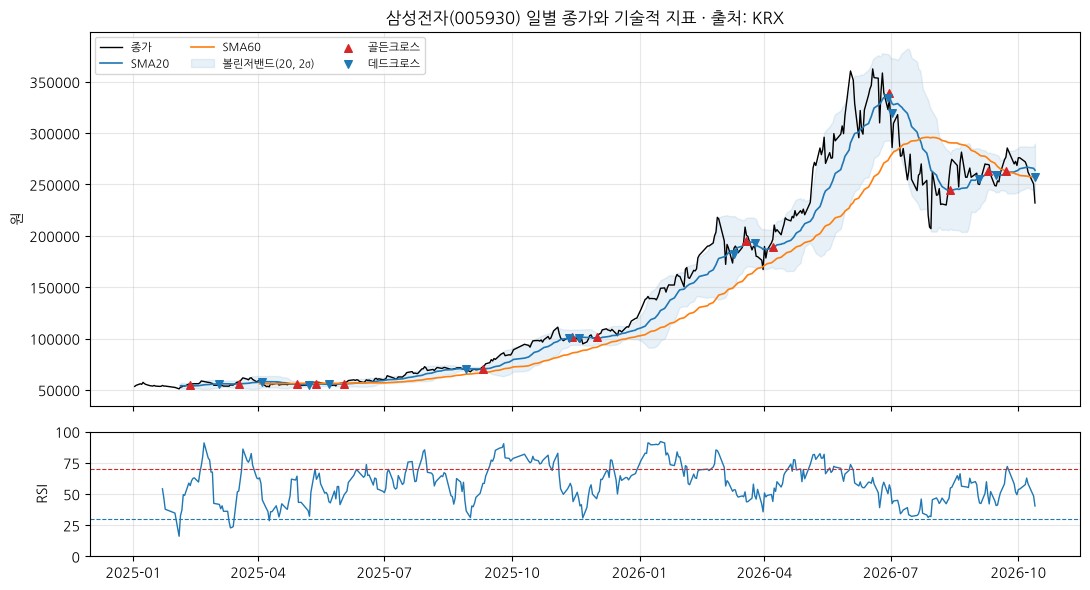

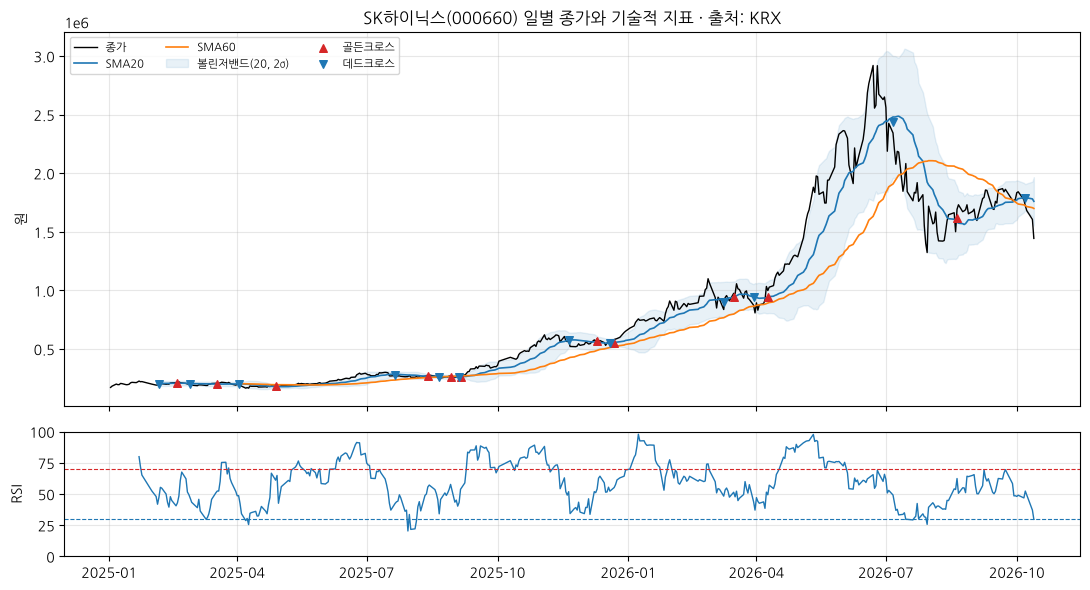

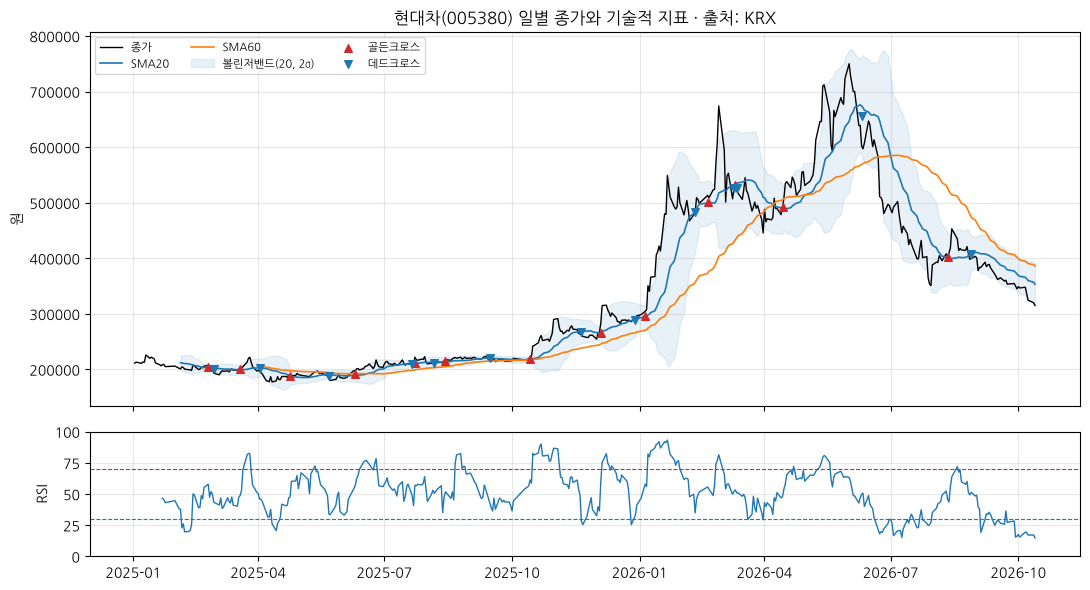

In [17]:
for code, name in STOCKS.items():
    d = frames[name]
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    ax1.plot(d["Date"], d["Close"], color="black", lw=1, label="종가")
    ax1.plot(d["Date"], d["SMA20"], lw=1.2, label="SMA20")
    ax1.plot(d["Date"], d["SMA60"], lw=1.2, label="SMA60")
    ax1.fill_between(d["Date"], d["BB_Lower"], d["BB_Upper"], color="tab:blue", alpha=0.1, label="볼린저밴드(20, 2σ)")
    g, dd = d[d["Cross"] == "golden"], d[d["Cross"] == "dead"]
    ax1.scatter(g["Date"], g["SMA5"], marker="^", color="tab:red", s=30, label="골든크로스", zorder=3)
    ax1.scatter(dd["Date"], dd["SMA5"], marker="v", color="tab:blue", s=30, label="데드크로스", zorder=3)
    ax1.set_title(f"{name}({code}) 일별 종가와 기술적 지표 · 출처: KRX"); ax1.set_ylabel("원")
    ax1.legend(loc="upper left", fontsize=8, ncol=3); ax1.grid(alpha=0.3)
    ax2.plot(d["Date"], d["RSI14"], lw=1, label="RSI14(단순)")
    ax2.axhline(70, ls="--", color="tab:red", lw=0.8); ax2.axhline(30, ls="--", color="tab:blue", lw=0.8)
    ax2.set_ylim(0, 100); ax2.set_ylabel("RSI"); ax2.grid(alpha=0.3)
    plt.tight_layout(); plt.savefig(f"fig_week05_{code}.png", dpi=120); plt.show()

### 2-7. 누적 수익률 비교 (KOSPI 대비)

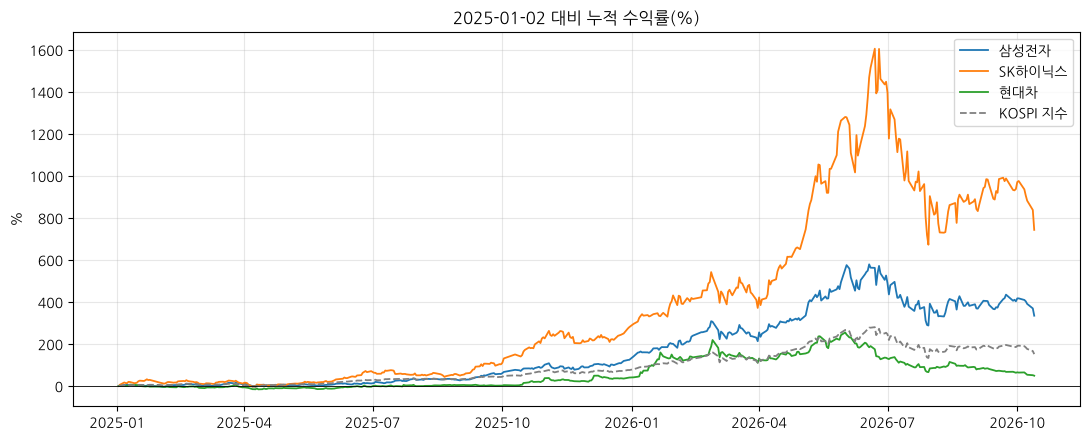

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for name, d in frames.items():
    ax.plot(d["Date"], d["CumReturnPct"], lw=1.3, label=name)
ax.plot(kospi_d["Date"], kospi_d["CumReturnPct"], color="gray", ls="--", lw=1.3, label="KOSPI 지수")
ax.axhline(0, color="black", lw=0.6)
ax.set_title("2025-01-02 대비 누적 수익률(%)"); ax.set_ylabel("%"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("fig_week05_cumreturn.png", dpi=120); plt.show()

### 2-8. 위험 비교 — 20일 변동성과 고점 대비 하락률

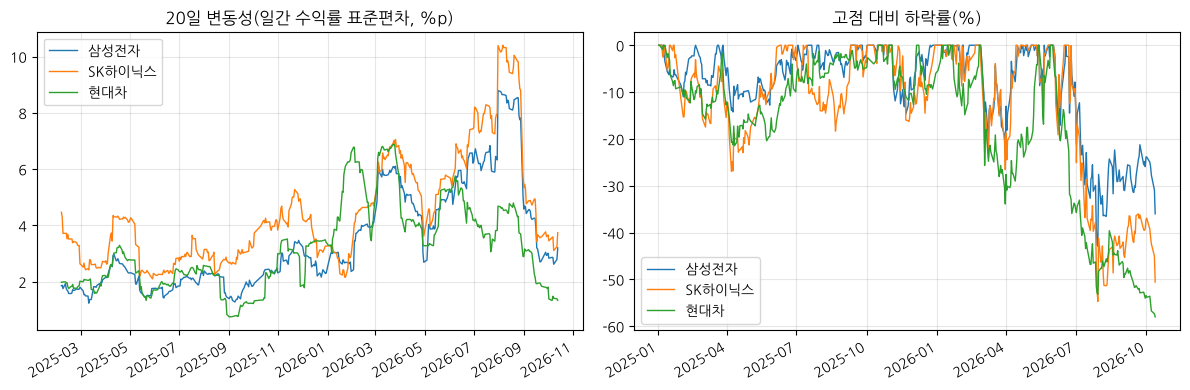

In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for name, d in frames.items():
    ax1.plot(d["Date"], d["Vol20Pct"], lw=1, label=name)
    ax2.plot(d["Date"], d["DrawdownPct"], lw=1, label=name)
ax1.set_title("20일 변동성(일간 수익률 표준편차, %p)"); ax1.legend(); ax1.grid(alpha=0.3)
ax2.set_title("고점 대비 하락률(%)"); ax2.legend(); ax2.grid(alpha=0.3)
fig.autofmt_xdate(); plt.tight_layout(); plt.savefig("fig_week05_risk.png", dpi=120); plt.show()

### 2-9. 최근 크로스 발생일과 RSI 계산 방식 비교

In [20]:
for name, d in frames.items():
    ev = d[d["Cross"] != ""].set_index("Date")[["Close", "SMA5", "SMA20", "Cross"]].tail(3)
    print(f"■ {name} 최근 크로스 3건"); print(ev.round(0).to_string(), "\n")

cmp = pd.DataFrame({name: {"RSI14 단순평균": round(d["RSI14"].iloc[-1], 1),
                           "RSI14 Wilder": round(d["RSI14_Wilder"].iloc[-1], 1),
                           "전체 기간 평균 |차이|": round((d["RSI14"] - d["RSI14_Wilder"]).abs().mean(), 1)}
                    for name, d in frames.items()}).T
cmp

■ 삼성전자 최근 크로스 3건
             Close      SMA5     SMA20   Cross
Date                                          
2026-09-15  248500  259100.0  260525.0    dead
2026-09-22  276500  263500.0  260700.0  golden
2026-10-13  232000  257000.0  263850.0    dead 

■ SK하이닉스 최근 크로스 3건
              Close       SMA5      SMA20   Cross
Date                                             
2026-07-06  2343000  2433000.0  2479550.0    dead
2026-08-20  1691000  1618200.0  1582700.0  golden
2026-10-07  1723000  1789200.0  1794700.0    dead 

■ 현대차 최근 크로스 3건
             Close      SMA5     SMA20   Cross
Date                                          
2026-06-10  602000  656000.0  673850.0    dead
2026-08-11  403000  402200.0  399425.0  golden
2026-08-28  399500  408100.0  409375.0    dead 



,RSI14 단순평균,RSI14 Wilder,전체 기간 평균 |차이|
삼성전자,40.4,34.4,6.1
SK하이닉스,29.7,31.4,6.8
현대차,14.7,21.9,6.9


### 해석 가이드 (결과표 '분석' 칸 작성법)
- **관찰 문장**으로 씁니다: "기준일 종가는 SMA20보다 낮다", "RSI14는 29.7로 30 이하 구간이다".
- **예언·추천 금지**: "곧 반등한다", "매수 기회다"는 지표가 말해 주지 않습니다.
- RSI는 계산 방식(단순/Wilder)에 따라 값이 다르므로 **방식을 함께 적습니다.** 증권사 HTS 값과 다를 수 있습니다.
- 크로스는 이동평균이 **이미 지난 가격**의 평균이라 늦게 나타납니다(후행 지표).

**토의:** ① 세 종목 모두 기간 누적수익률이 플러스인데 MDD는 −40% 이하입니다. 두 숫자를 함께 봐야 하는 이유는?
② 마지막 날(2026-10-13) 큰 하락이 있었습니다. **이 표만으로** 하락 원인을 말할 수 있나요?

---
# 워크북 3 · AI 보조 요약 근거 검증

흐름: **① 규칙으로 사실 정리 → ② 같은 표로 AI에게 요약 요청 → ③ 숫자·표현 검증 → ④ 검증표 작성**

⚠ AI 채팅에 개인정보, 계좌 정보, API 키를 붙여 넣지 않습니다.

### 3-1. 전통적(규칙 기반) 분석 — 데이터로 확인 가능한 사실만

In [21]:
def rule_facts(row):                       # row = 2-4 지표표(table)의 한 행
    r = row["RSI14"]
    return {
        "이동평균": "SMA5 > SMA20 (단기 평균이 중기 평균보다 높음)" if row["SMA5"] > row["SMA20"]
                    else "SMA5 < SMA20 (단기 평균이 중기 평균보다 낮음)",
        "종가 위치": "종가 > SMA20" if row["종가"] > row["SMA20"] else "종가 < SMA20",
        "RSI 구간": f"{r:.1f} → " + ("70 이상(상대적 과열)" if r >= 70 else "30 이하(상대적 침체)" if r <= 30 else "30~70 중립"),
        "볼린저": "상단 밴드 위" if row["종가"] > row["BB_Upper"] else "하단 밴드 아래" if row["종가"] < row["BB_Lower"] else "밴드 안",
        "변동성": f"{row['Vol20Pct']:.2f}%p (3종목 중 {int(row['변동성순위'])}위)",
    }

facts = pd.DataFrame({row["종목"]: rule_facts(row) for _, row in table.iterrows()}).T
facts

,이동평균,종가 위치,RSI 구간,볼린저,변동성
삼성전자,SMA5 < SMA20 (단기 평균이 중기 평균보다 낮음),종가 < SMA20,40.4 → 30~70 중립,하단 밴드 아래,3.20%p (3종목 중 2위)
SK하이닉스,SMA5 < SMA20 (단기 평균이 중기 평균보다 낮음),종가 < SMA20,29.7 → 30 이하(상대적 침체),하단 밴드 아래,3.74%p (3종목 중 1위)
현대차,SMA5 < SMA20 (단기 평균이 중기 평균보다 낮음),종가 < SMA20,14.7 → 30 이하(상대적 침체),밴드 안,1.34%p (3종목 중 3위)


### 3-2. AI에게 보낼 프롬프트 만들기

In [22]:
PROMPT = """아래는 {date} 기준 국내 주식 3종목의 기술적 지표 표입니다(출처: 한국거래소 일별 시세로 직접 계산).
규칙:
1) 표에 있는 숫자만 사용하세요. 실적, 뉴스, 수급(외국인·기관), 전망, 목표주가는 쓰지 마세요.
2) 종목별로 (1) SMA5와 SMA20 비교, (2) RSI14 위치(30 이하/30~70/70 이상), (3) 3종목 중 변동성 순위, (4) 이 표만으로는 알 수 없는 점 을 각각 한 문장으로 쓰세요.
3) 각 문장 끝에 근거가 된 열 이름을 [열이름] 형태로 붙이세요.
4) 표로 확인할 수 없는 내용은 '확인 불가'라고 쓰세요. 매수·매도 추천은 하지 마세요.

표:
{table}
"""
cols = ["종목", "기준일", "종가", "일간수익률%", "SMA5", "SMA20", "RSI14", "Vol20Pct", "BB_Upper", "BB_Lower"]
prompt = PROMPT.format(date=table["기준일"].iloc[0], table=table[cols].to_markdown(index=False))
print(prompt)

아래는 2026-10-13 기준 국내 주식 3종목의 기술적 지표 표입니다(출처: 한국거래소 일별 시세로 직접 계산).
규칙:
1) 표에 있는 숫자만 사용하세요. 실적, 뉴스, 수급(외국인·기관), 전망, 목표주가는 쓰지 마세요.
2) 종목별로 (1) SMA5와 SMA20 비교, (2) RSI14 위치(30 이하/30~70/70 이상), (3) 3종목 중 변동성 순위, (4) 이 표만으로는 알 수 없는 점 을 각각 한 문장으로 쓰세요.
3) 각 문장 끝에 근거가 된 열 이름을 [열이름] 형태로 붙이세요.
4) 표로 확인할 수 없는 내용은 '확인 불가'라고 쓰세요. 매수·매도 추천은 하지 마세요.

표:
| 종목       | 기준일     |    종가 |   일간수익률% |    SMA5 |   SMA20 |   RSI14 |   Vol20Pct |   BB_Upper |   BB_Lower |
|:-----------|:-----------|--------:|--------------:|--------:|--------:|--------:|-----------:|-----------:|-----------:|
| 삼성전자   | 2026-10-13 |  232000 |         -7.39 |  257000 |  263850 |    40.4 |       3.2  |     289769 |     237931 |
| SK하이닉스 | 2026-10-13 | 1443000 |        -10.09 | 1645000 | 1759550 |    29.7 |       3.74 |    1966202 |    1552898 |
| 현대차     | 2026-10-13 |  315000 |         -1.56 |  328700 |  353075 |    14.7 |       1.34 |     391229 |     314921 |



### 3-3. AI 응답 붙여넣기
1. 위 출력 전체를 복사해 ChatGPT / Claude / Gemini 중 하나에 붙여 넣습니다. (사용한 서비스·모델 이름과 시각을 기록)
2. AI의 답을 **그대로** 아래 `ai_text` 따옴표 안에 붙여 넣고 실행합니다.
3. 비교 실험(선택): 규칙 1)~4)를 지운 **약한 프롬프트**("이 표를 보고 3종목을 분석해 줘")로도 받아 결과를 비교합니다.

완성본에는 검증 연습용 **예시 응답**(가상의 AI 답변, 오류 포함)이 들어 있습니다. 실제 수업에서는 본인이 받은 AI 응답으로 바꿔 넣습니다.

In [23]:
ai_text = """
[예시 응답 — 강의자가 검증 연습용으로 작성한 가상의 AI 답변이며, 의도적인 오류 3곳이 들어 있음]
삼성전자: SMA5(257,000)가 SMA20(263,850)보다 낮아 단기 평균이 중기 평균 아래에 있습니다 [SMA5, SMA20].
RSI14는 40.4로 중립 구간입니다 [RSI14]. 변동성은 3종목 중 2위입니다 [Vol20Pct].
SK하이닉스: SMA5가 SMA20보다 낮습니다 [SMA5, SMA20]. RSI14는 29.7로 30 이하 구간입니다 [RSI14].
반도체 업황 둔화 우려로 외국인 매도가 이어지며 7.2% 급락했습니다 [일간수익률%].
현대차: RSI14가 24.7로 침체 구간이며 변동성은 가장 낮습니다 [RSI14, Vol20Pct].
과매도 구간이므로 단기 반등 가능성이 높아 매수 관점이 유효합니다.
"""

### 3-4. 숫자 검증 — AI가 쓴 숫자가 표에 있는가?

In [24]:
import re

def check_numbers(text, table, tol=0.01):
    vals = pd.to_numeric(table.select_dtypes("number").stack(), errors="coerce").dropna().values
    allowed = {1, 2, 3, 4, 5, 14, 20, 30, 60, 70}           # 순위·기간·기준선 숫자
    out = []
    # 영문자에 붙은 숫자(SMA5, RSI14 등 열 이름)는 제외하고, 1,234,567 같은 천 단위 쉼표 숫자는 하나로 읽는다
    for tok in re.findall(r"(?<![A-Za-z\d.])-?(?:\d{1,3}(?:,\d{3})+|\d+)(?:\.\d+)?", text):
        v = float(tok.replace(",", ""))
        if v in allowed:
            status = "기준/기간 숫자"
        elif np.any(np.isclose(vals, v, rtol=tol, atol=0.051)):
            status = "표에 있음 ✔"
        else:
            status = "표에 없음 ✘ → 직접 확인"
        out.append({"AI가 쓴 숫자": tok, "판정": status})
    return pd.DataFrame(out).drop_duplicates().reset_index(drop=True)

num_check = check_numbers(ai_text, table)
num_check

,AI가 쓴 숫자,판정
0,3,기준/기간 숫자
1,"257,000",표에 있음 ✔
2,"263,850",표에 있음 ✔
3,40.4,표에 있음 ✔
4,2,기준/기간 숫자
5,29.7,표에 있음 ✔
6,30,기준/기간 숫자
7,7.2,표에 없음 ✘ → 직접 확인
8,24.7,표에 없음 ✘ → 직접 확인


### 3-5. 표현 검증 — 표 밖의 정보·추천·인과 표현 찾기

In [25]:
RISKY = {"표 밖 정보": ["뉴스", "실적", "업황", "외국인", "기관", "금리", "환율", "정책", "발표"],
         "추천·예측": ["매수", "매도", "반등", "상승할", "하락할", "전망", "목표", "유효", "기회"],
         "인과 단정": ["때문", "으로 인해", "우려로", "영향으로"]}

sentences = [s.strip() for s in re.split(r"(?<=[.!?])\s+|\n", ai_text) if s.strip()]
rows = []
for s in sentences:
    hits = [f"{k}:{w}" for k, ws in RISKY.items() for w in ws if w in s]
    has_src = bool(re.search(r"\[[^\]]+\]", s))
    rows.append({"AI 문장": s[:70], "근거 열 표기": "있음" if has_src else "없음",
                 "위험 표현": ", ".join(hits) if hits else "-"})
expr_check = pd.DataFrame(rows)
expr_check

,AI 문장,근거 열 표기,위험 표현
0,"[예시 응답 — 강의자가 검증 연습용으로 작성한 가상의 AI 답변이며, 의도적인 오...",있음,-
1,"삼성전자: SMA5(257,000)가 SMA20(263,850)보다 낮아 단기 평균...",있음,-
2,RSI14는 40.4로 중립 구간입니다 [RSI14].,있음,-
3,변동성은 3종목 중 2위입니다 [Vol20Pct].,있음,-
4,"SK하이닉스: SMA5가 SMA20보다 낮습니다 [SMA5, SMA20].",있음,-
5,RSI14는 29.7로 30 이하 구간입니다 [RSI14].,있음,-
6,반도체 업황 둔화 우려로 외국인 매도가 이어지며 7.2% 급락했습니다 [일간수익률%].,있음,"표 밖 정보:업황, 표 밖 정보:외국인, 추천·예측:매도, 인과 단정:우려로"
7,"현대차: RSI14가 24.7로 침체 구간이며 변동성은 가장 낮습니다 [RSI14,...",있음,-
8,과매도 구간이므로 단기 반등 가능성이 높아 매수 관점이 유효합니다.,없음,"추천·예측:매수, 추천·예측:매도, 추천·예측:반등, 추천·예측:유효"


> 키워드 검사는 **1차 필터**입니다. 예: '과매도'라는 지표 용어에도 '매도'가 걸리고, 키워드 목록에 없는 새 표현은 놓칩니다.
> 걸린 문장은 표와 직접 대조해 **사람이 최종 판정**합니다.

### 3-6. 검증표 작성 · 저장 (제출물)

In [26]:
verify = pd.DataFrame({
    "종목": table["종목"],
    "전통적 분석 사실": [" / ".join(f"{k}: {v}" for k, v in rule_facts(r).items()) for _, r in table.iterrows()],
    "AI 설명(요약)": "",          # ← 직접 입력
    "근거 데이터 열": "",          # ← AI가 붙인 [열이름]
    "일치 여부(일치/불일치/일부)": "",
    "과장·환각 여부(구체적으로)": "",
})
verify.to_csv("week05_ai_verification.csv", index=False, encoding="utf-8-sig")
verify

,종목,전통적 분석 사실,AI 설명(요약),근거 데이터 열,일치 여부(일치/불일치/일부),과장·환각 여부(구체적으로)
0,삼성전자,이동평균: SMA5 < SMA20 (단기 평균이 중기 평균보다 낮음) / 종가 위치...,,,,
1,SK하이닉스,이동평균: SMA5 < SMA20 (단기 평균이 중기 평균보다 낮음) / 종가 위치...,,,,
2,현대차,이동평균: SMA5 < SMA20 (단기 평균이 중기 평균보다 낮음) / 종가 위치...,,,,



### 예시 응답의 오류 (강의자용 정답)
| 위치 | 문제 | 판별 방법 |
|---|---|---|
| SK하이닉스 "7.2% 급락" | 숫자 오류: 표의 일간수익률은 −10.09% | 3-4 숫자 검증에서 '표에 없음' |
| SK하이닉스 "반도체 업황 둔화 우려로 외국인 매도" | 표 밖 정보·인과 단정(환각) | 3-5 '표 밖 정보', '인과 단정' |
| 현대차 "RSI14가 24.7" | 숫자 오류: 표의 RSI14는 14.7 | 3-4 숫자 검증 |
| 현대차 "단기 반등 가능성…매수 관점이 유효" | 예측·매수 추천(금지 규칙 위반), 근거 열 없음 | 3-5 '추천·예측', 근거 열 '없음' |


### 제출물
1. `week05_clean_3stocks.csv`, `week05_indicators_latest.csv`, 그림 2개 이상
2. 사용한 프롬프트 전문 + AI 응답 원문 + 서비스·모델명·시각
3. `week05_ai_verification.csv` (빈칸 채운 것) + 일치/불일치 분석 3문장 이상
4. 이 데이터만으로 알 수 없는 것 2가지와, 확인하려면 필요한 추가 데이터

### 더 해보기 (선택)
- 기준일을 바꿔 다시 실행: `latest_table(frames, "2026-06-01")` → 같은 프롬프트로 AI 요약을 받아 비교
- 종목 추가: 수업 저장소에 없는 종목은 `Week05_데이터수집_API가이드.ipynb`의 방법 B~D로 수집